# Water Mass Division Overview

This notebook visualizes time-series trends of various water quality parameters across the Seto Inland Sea, grouped by **Water Mass Division**.

It loads the primary cleaned dataset (`data/processed/merged_gdf.feather`) and provides interactive widgets to filter the data by Season and Layer before generating the comparative grid plots.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import geopandas as gpd
import ipywidgets as widgets
from IPython.display import display
import sys
from pathlib import Path

# Ensure local scripts are importable
project_root = Path("../").resolve()
if str(project_root) not in sys.path:
    sys.path.append(str(project_root))

from scripts.paths import ProjectPaths

import warnings
warnings.filterwarnings('ignore')

# Configure plotting
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

## Data Loading

We load the global `merged_gdf.feather` file. This dataset contains all stations, seasons, layers, and multiple water quality parameters.

In [6]:
# Load the primary dataset
data_path = ProjectPaths.MERGED_DATA_FILE
print(f"Loading data from {data_path}...")
merged_gdf = gpd.read_feather(data_path)
print(f"Data loaded. Shape: {merged_gdf.shape}")

# Ensure year is numeric for plotting
merged_gdf['year'] = pd.to_numeric(merged_gdf['year'], errors='coerce')

# Fix the confusing "—" division names for Tokyo and Ise Bay
# We set their division to equal their 'watermass_name' (e.g. "Tokyo Bay")
merged_gdf['division'] = np.where(
    merged_gdf['division'] == '—', 
    merged_gdf['watermass_name'], 
    merged_gdf['division']
)

# Extract robust lookup of Division mapping
# (Useful to keep colours consistent even if a specific subset misses a division)
station_division = (
    merged_gdf[['zettaicode', 'division']]
    .dropna()
    .drop_duplicates('zettaicode')
    .set_index('zettaicode')['division']
)

all_divisions = sorted(station_division.unique())
palette = sns.color_palette("tab10", n_colors=len(all_divisions))
global_div_colour = dict(zip(all_divisions, palette))

Loading data from /home/reyha/SIS_Analysis_WSL/data/processed/merged_gdf.feather...
Data loaded. Shape: (65643, 65)


In [7]:
# Calculate the total number of stations for each water mass division
division_counts = (
    station_division.value_counts()
    .sort_index()
    .rename("station_count")
    .to_frame()
)

# Explicitly append the True Grand Total to the bottom of the table
division_counts.loc['=== TOTAL STATIONS ==='] = division_counts['station_count'].sum()

print("Summary of Stations by Water Mass Division:")
display(division_counts)

Summary of Stations by Water Mass Division:


,station_count
division,
Aki Nada,7
Bingo Nada,8
Bisan Seto,9
Bungo Channel,12
Harima Nada,14
Hibiki Nada,3
Hiroshima Bay,9
Hiuchi Nada,9
Ise Bay,33


## Interactive Parameter Exploration

Select the **Season**, **Layer** (`saisuipoin`), and **Parameter** below. The plot will update automatically to display the yearly average time series of that parameter, separated into subplots by `division`.

In [3]:
def plot_parameter_by_division(season, layer_val, parameter):
    # 1. Filter Data
    subset = merged_gdf[
        (merged_gdf['season'] == season) & 
        (merged_gdf['saisuipoin'] == layer_val)
    ].copy()
    
    if subset.empty:
        print(f"No data found for Season: {season}, Layer: {layer_val}")
        return
        
    # 2. Aggregate to yearly means per station
    # Note: We group by year and zettaicode, then take the mean of the target parameter.
    yearly_param = (
        subset.groupby(['zettaicode', 'year'])[parameter]
        .mean()
        .reset_index()
    )
    
    # Append the division info
    yearly_param['division'] = yearly_param['zettaicode'].map(station_division)
    
    # Filter out records where the parameter is NaN
    yearly_param = yearly_param.dropna(subset=[parameter, 'division'])
    
    if yearly_param.empty:
        print(f"No numeric data found for parameter '{parameter}' in this subset.")
        return

    # 3. Figure Setup
    # Determine which divisions actually exist in this specific subset
    divisions_present = sorted(yearly_param['division'].unique())
    
    ncols = 2
    nrows = -(-len(divisions_present) // ncols)  # Ceiling division
    
    fig, axes = plt.subplots(nrows, ncols, 
                             figsize=(14, 4 * nrows), 
                             sharey=False, sharex=True)
    
    # Ensure axes is iterable even if there is only 1 subplot
    if nrows * ncols == 1:
        axes = [axes]
    else:
        axes = axes.flatten()
        
    # 4. Plotting
    for ax, div in zip(axes, divisions_present):
        div_data = yearly_param[yearly_param['division'] == div]
        stations_in_div = div_data['zettaicode'].unique()
        
        for station in stations_in_div:
            stn_data = div_data[div_data['zettaicode'] == station]
            # Sort by year to ensure clean lines
            stn_data = stn_data.sort_values('year')
            
            ax.plot(
                stn_data['year'], stn_data[parameter],
                color=global_div_colour.get(div, 'grey'),
                alpha=0.55, linewidth=1.0, label=station
            )
            
        ax.set_title(f'Division: {div} (n={len(stations_in_div)} stations)', 
                     fontsize=11, fontweight='bold')
        ax.set_xlabel('Year', fontsize=9)
        ax.set_ylabel(parameter, fontsize=9)
        ax.grid(True, linestyle='--', alpha=0.4)
        ax.tick_params(axis='x', rotation=45)
        
    # Hide any unused subplots
    for ax in axes[len(divisions_present):]:
        ax.set_visible(False)

    layer_name = 'Surface' if layer_val == 1 else 'Bottom'
    fig.suptitle(f'{parameter} Time Series by Division ({season}, {layer_name})',
                 fontsize=14, fontweight='bold', y=1.02)
    
    plt.tight_layout()
    plt.show()

# Create Interactive Widgets
season_dropdown = widgets.Dropdown(
    options=['Spring', 'Summer', 'Autumn', 'Winter'],
    value='Summer',
    description='Season:'
)

layer_dropdown = widgets.Dropdown(
    options=[('Surface (1)', 1), ('Bottom (2)', 2)],
    value=2,
    description='Layer:'
)

parameter_dropdown = widgets.Dropdown(
    options=['do_', 'temp', 'salt', 'ph', 'cod', 'tn', 'tp', 'chlorophyl', 'clearness', 'depth'],
    value='do_',
    description='Parameter:'
)

out = widgets.interactive_output(plot_parameter_by_division, {
    'season': season_dropdown,
    'layer_val': layer_dropdown,
    'parameter': parameter_dropdown
})

display(widgets.HBox([season_dropdown, layer_dropdown, parameter_dropdown]))
display(out)

Output()

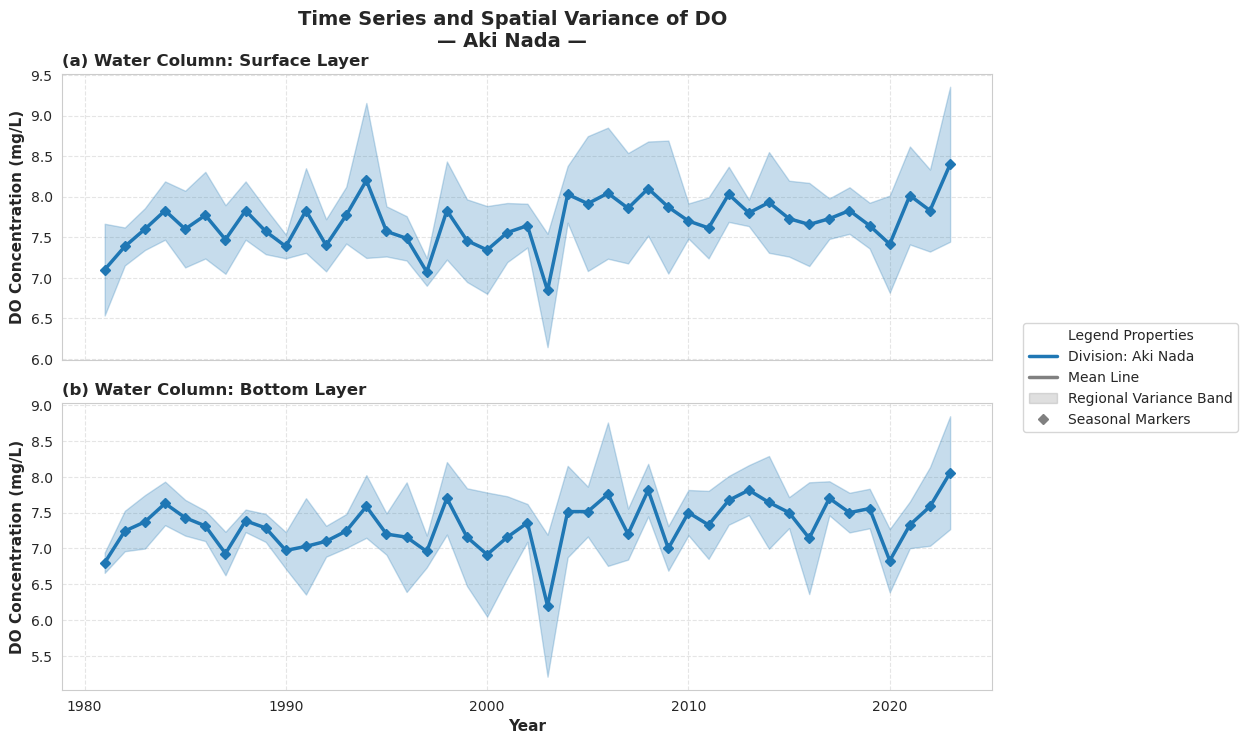

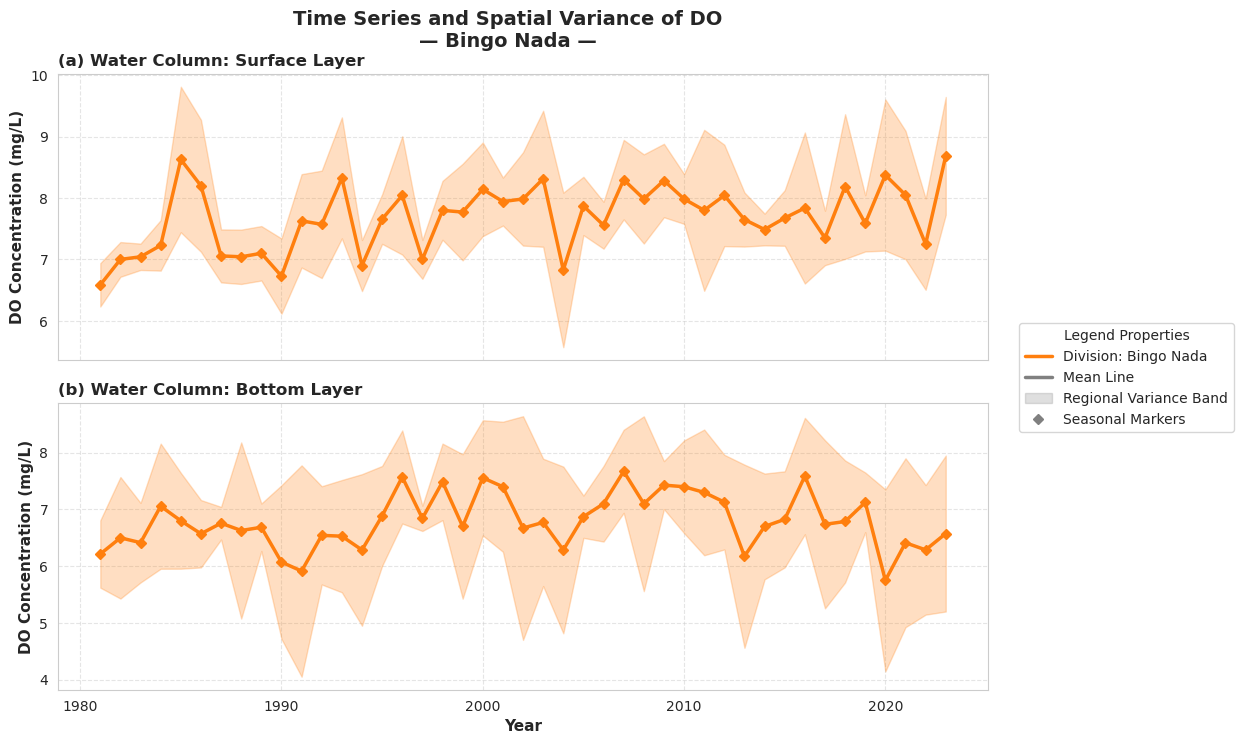

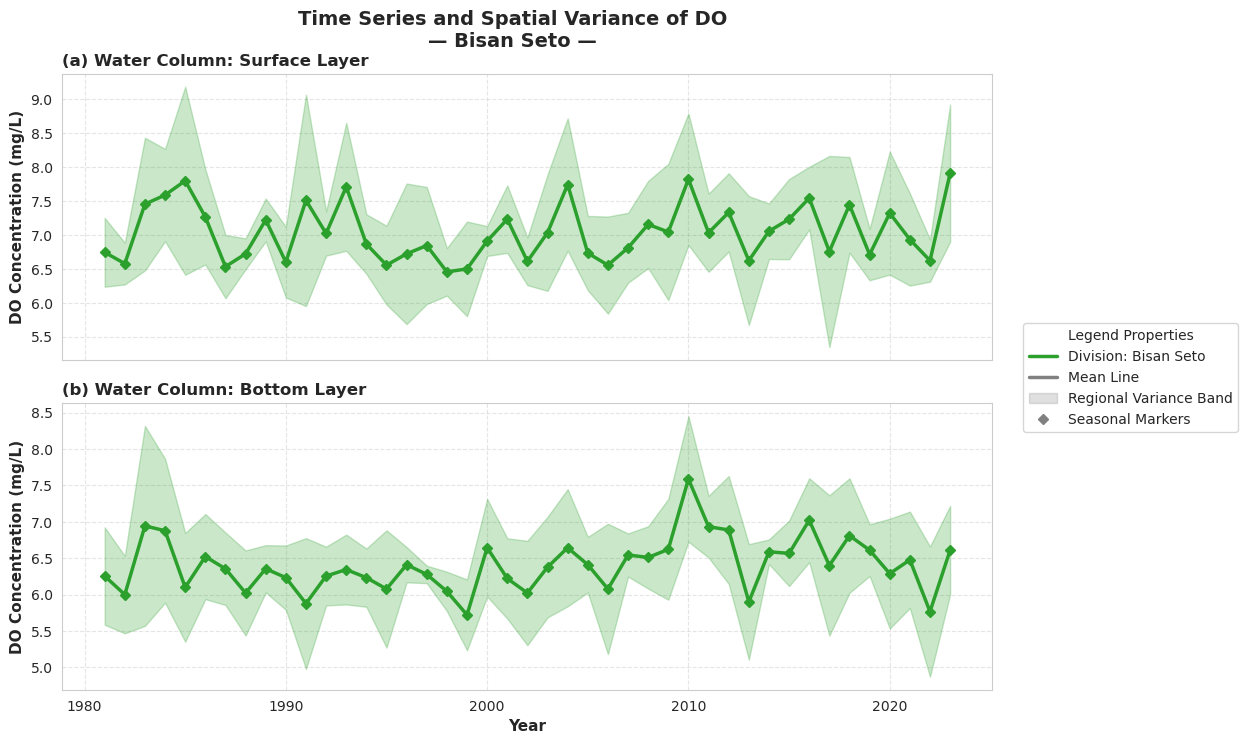

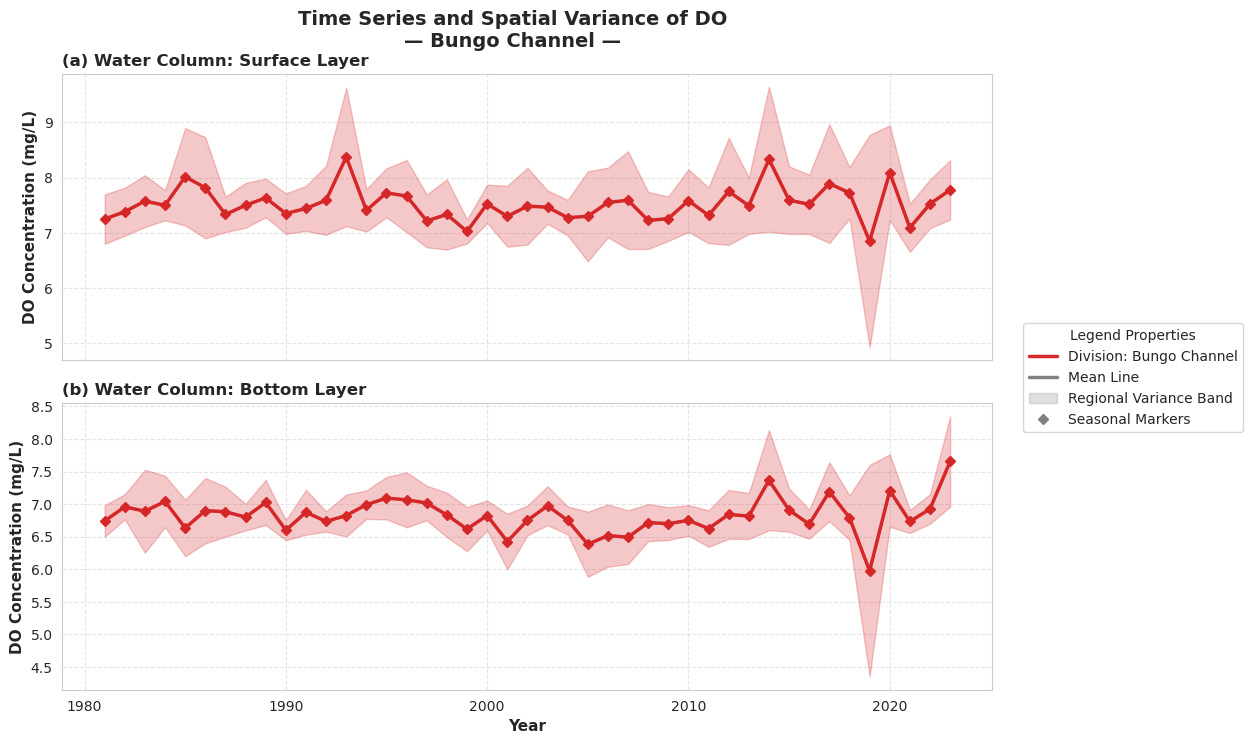

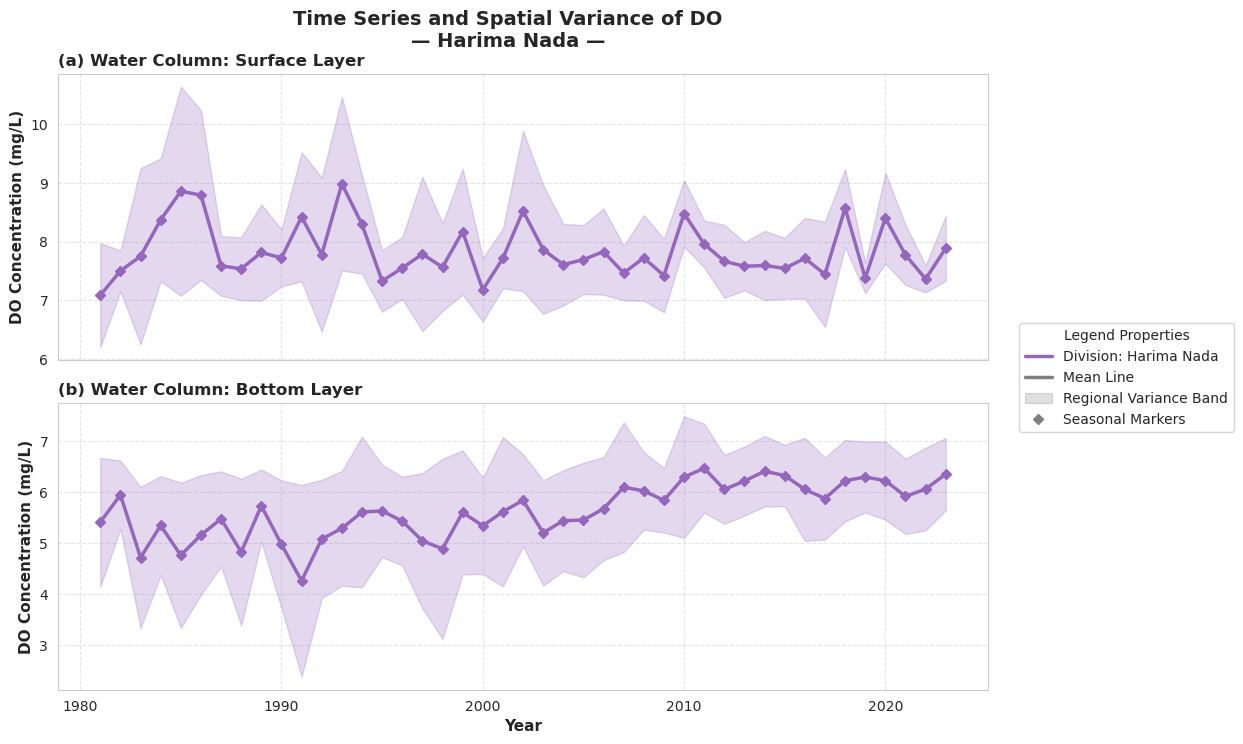

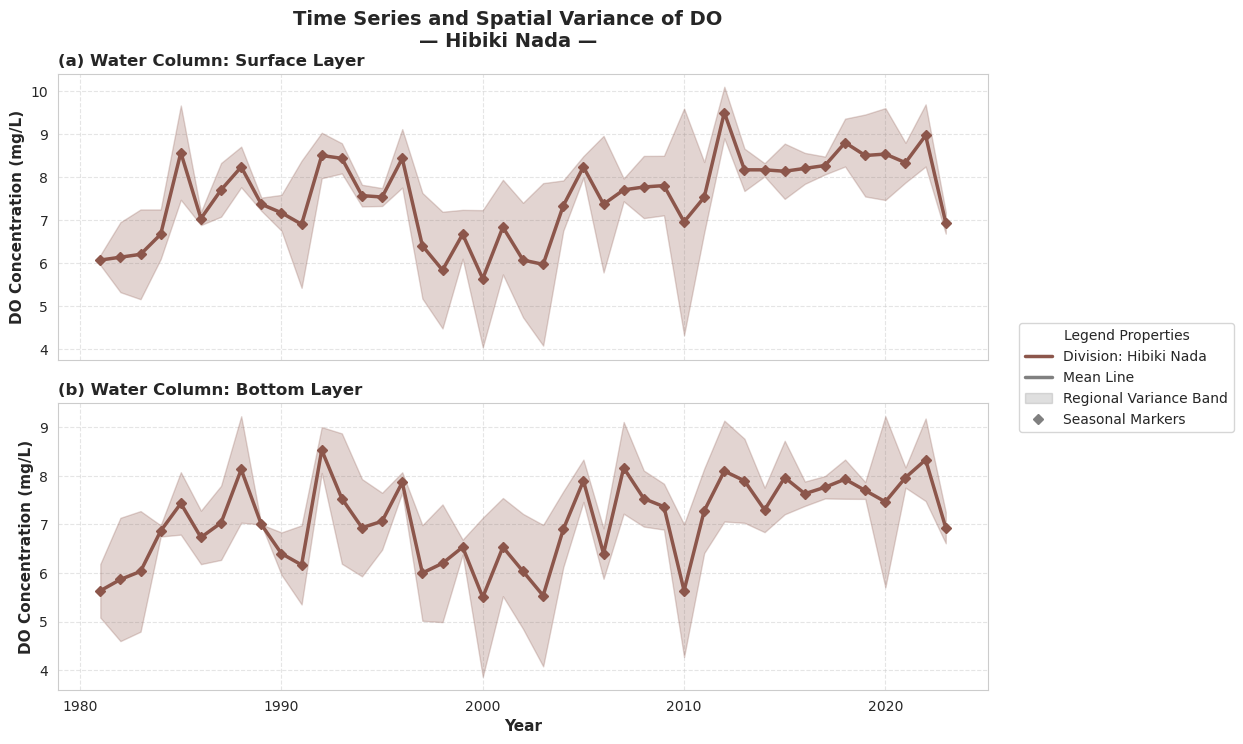

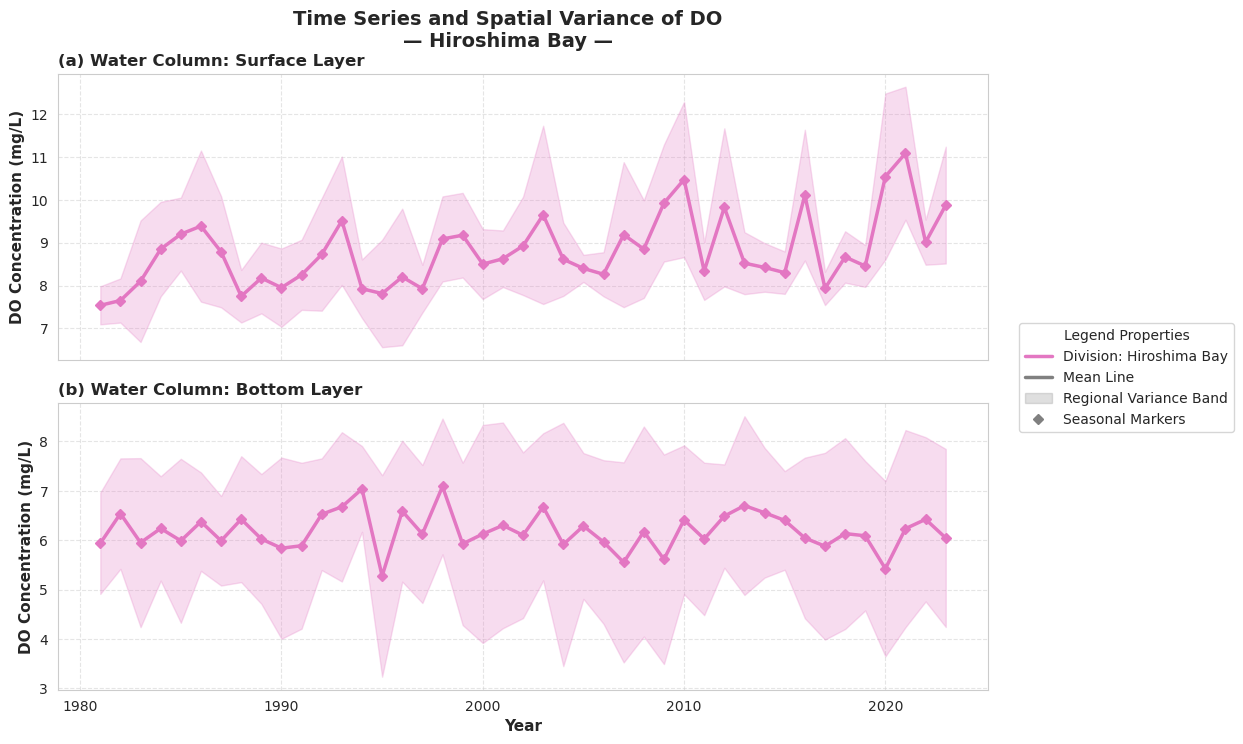

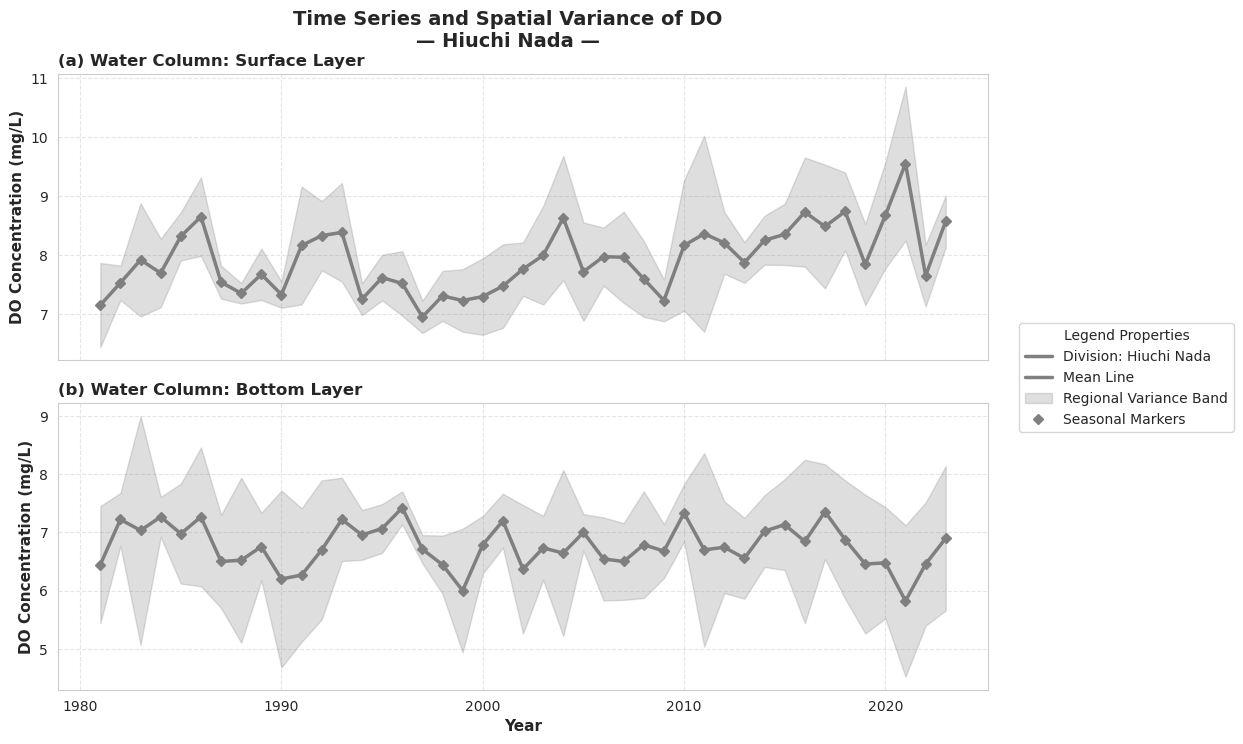

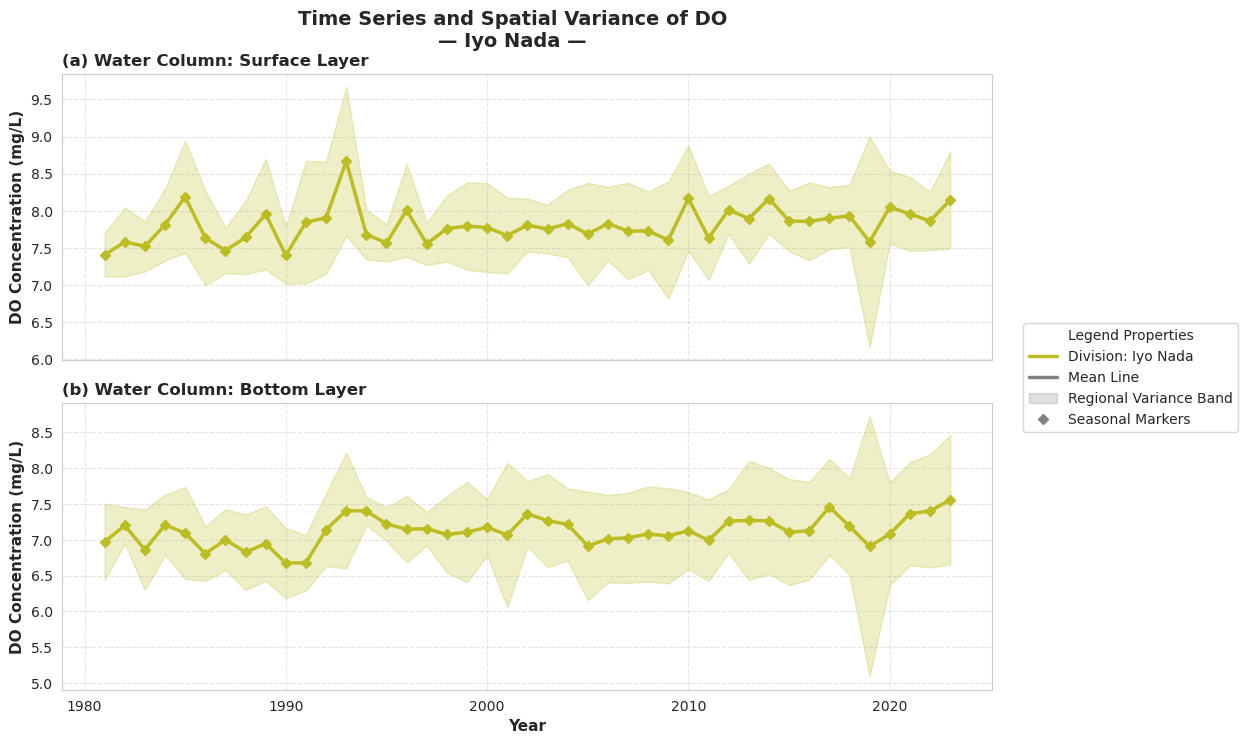

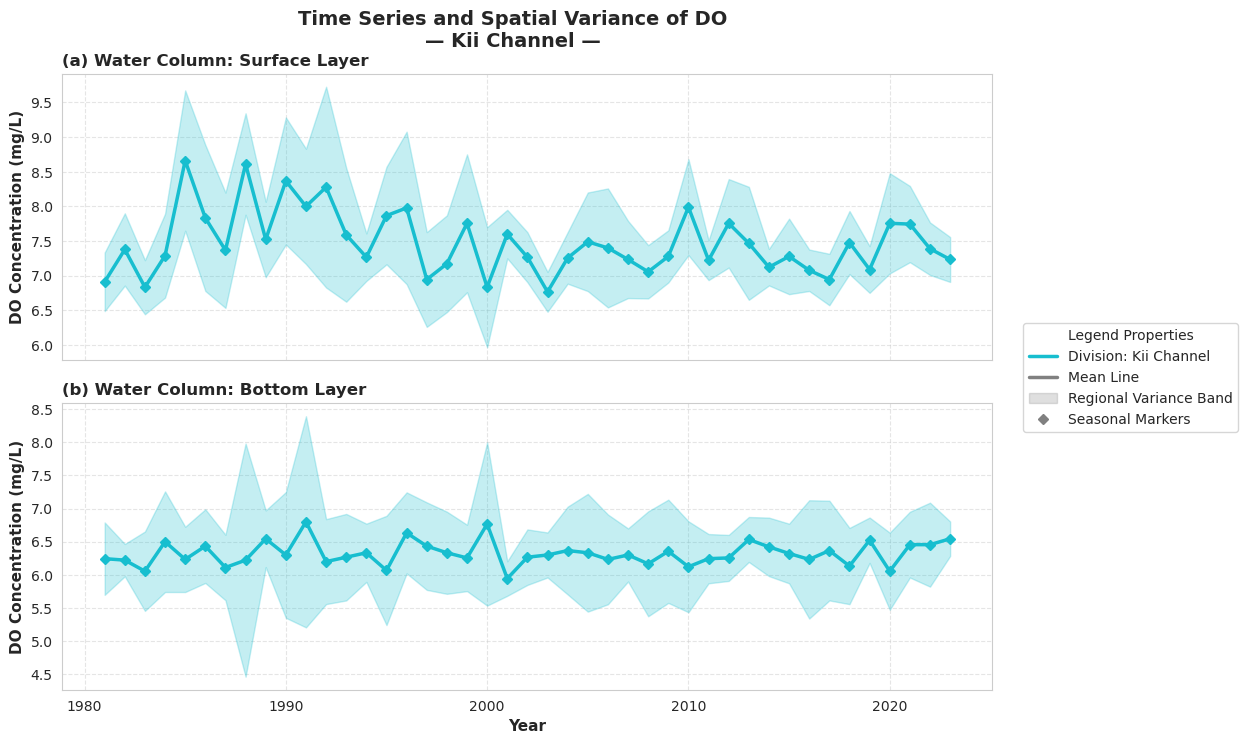

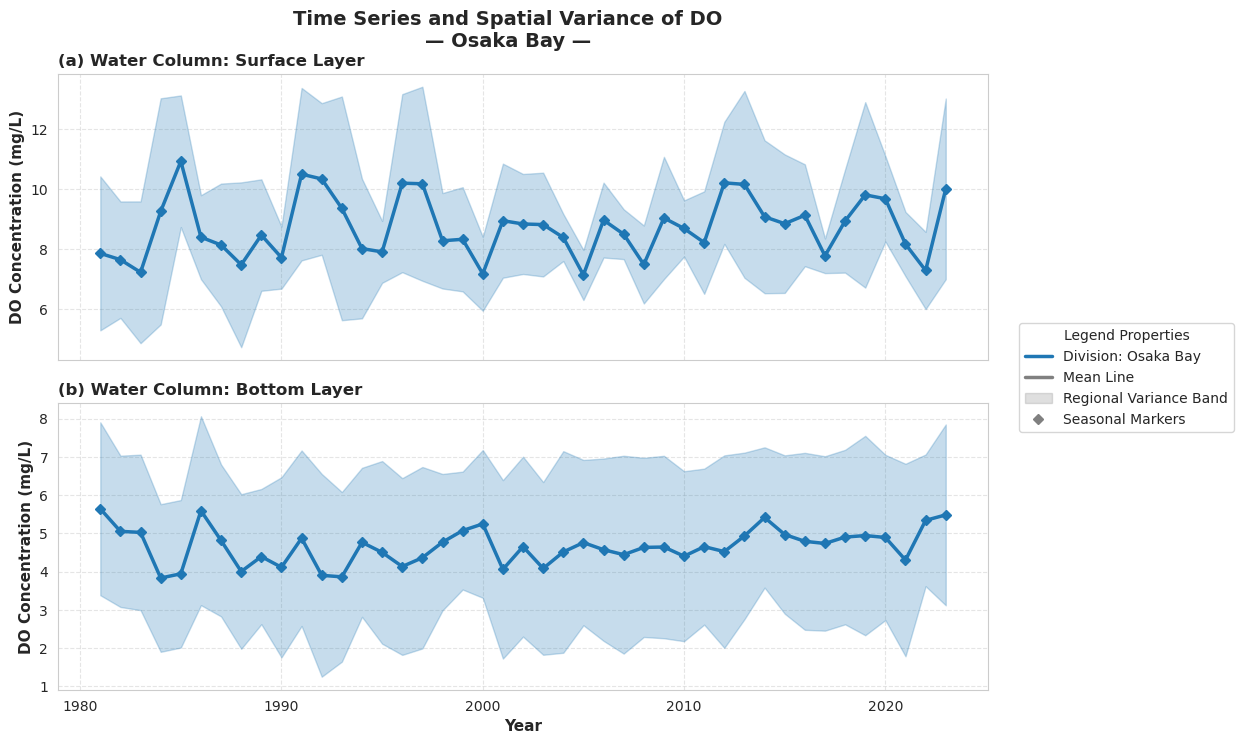

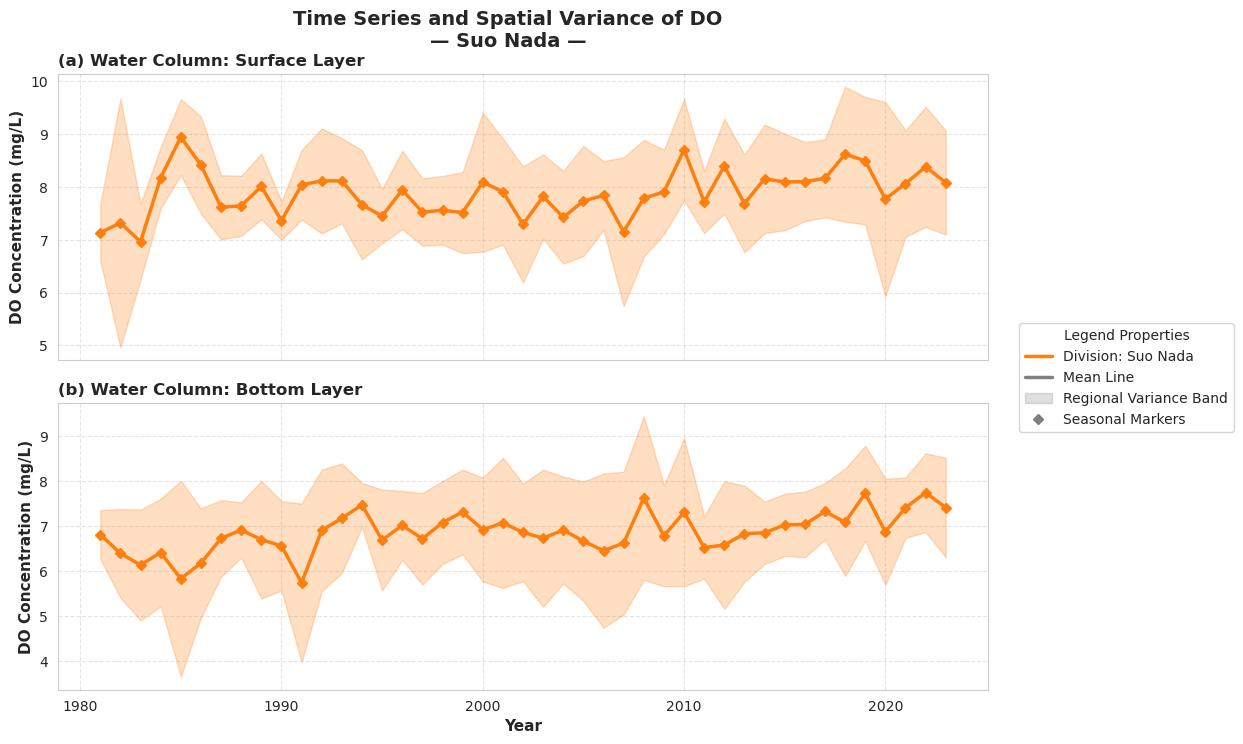

In [6]:
import matplotlib.pyplot as plt
import matplotlib.lines as mlines
import matplotlib.patches as mpatches

# ==============================================================================
# Custom Parameter Configuration
# ==============================================================================
target_parameter = 'do_'  # Parameter to plot (e.g., 'do_', 'temp', 'salt')
target_season = 'Summer'
# ==============================================================================

# Ensure we use the existing mapping of station to division
if 'station_division' not in locals():
    station_division = (
        merged_gdf[['zettaicode', 'division']]
        .dropna()
        .drop_duplicates('zettaicode')
        .set_index('zettaicode')['division']
    )

# Get a sorted list of all unique divisions
all_divisions = sorted(station_division.unique())

# 1. Filter the main dataset for the chosen season
subset = merged_gdf[merged_gdf['season'] == target_season].copy()
subset = subset.dropna(subset=[target_parameter])

# 2. Pre-calculate statistics for the entire subset to optimize the loop
# Group and calculate yearly mean per station first (normalizes uneven spatial sampling density)
yearly_stn_all = subset.groupby(['zettaicode', 'year', 'saisuipoin'])[target_parameter].mean().reset_index()
yearly_stn_all['division'] = yearly_stn_all['zettaicode'].map(station_division)
yearly_stn_all = yearly_stn_all.dropna(subset=['division', target_parameter])

# Calculate the Regional Mean and Standard Deviation (Spatial Variance)
regional_stats_all = yearly_stn_all.groupby(['year', 'division', 'saisuipoin'])[target_parameter].agg(['mean', 'std']).reset_index()

# Y-axis label logic: pull from MappingConfig if available, else fallback
try:
    from scripts.mapping_config import MappingConfig
    var_cfg = MappingConfig.get_var_settings(target_parameter)
    y_label = var_cfg.get('label', target_parameter)
except Exception:
    y_label = target_parameter

param_name = target_parameter.replace('_', '').upper() if target_parameter == 'do_' else target_parameter.title()

# 3. Loop through each division and create a separate plot
for div in all_divisions:
    
    div_data_all = regional_stats_all[regional_stats_all['division'] == div]
    
    # Skip plotting if there is no data for this division in the specified season
    if div_data_all.empty:
        continue
        
    # Get the assigned color for consistency
    color = global_div_colour.get(div, 'grey')
    
    # Set up a figure with two subplots displaying Surface and Bottom, sharing the x-axis
    fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)
    
    # Helper function to plot each layer for the current division
    def plot_layer(ax, layer_val, layer_title, marker_letter):
        div_data = div_data_all[div_data_all['saisuipoin'] == layer_val].sort_values('year')
        
        if not div_data.empty:
            # Plot Regional Mean Line with markers
            ax.plot(div_data['year'], div_data['mean'], marker='D', markersize=5, 
                    linewidth=2.5, label=div, color=color)
            
            # Plot Regional Variance Band (standard deviation ribbon)
            ax.fill_between(div_data['year'], 
                            div_data['mean'] - div_data['std'], 
                            div_data['mean'] + div_data['std'], 
                            color=color, alpha=0.25)

        # Subplot styling exactly matching the example structure
        ax.set_title(f"({marker_letter}) Water Column: {layer_title}", loc='left', fontsize=12, fontweight='bold')
        ax.set_ylabel(y_label, fontsize=11, fontweight='bold')
        ax.grid(True, linestyle='--', alpha=0.5)

    # Execute the plotting function for Surface and Bottom layers
    plot_layer(axes[0], 1, "Surface Layer", "a")
    plot_layer(axes[1], 2, "Bottom Layer", "b")

    # Configure the X-axis exclusively on the bottom plot
    axes[1].set_xlabel("Year", fontsize=11, fontweight='bold')

    # Add Custom Legend Guidance Entries
    mean_line_mock = mlines.Line2D([], [], color='grey', linewidth=2.5, label='Mean Line')
    variance_mock = mpatches.Patch(color='grey', alpha=0.25, label='Regional Variance Band')
    marker_mock = mlines.Line2D([], [], color='grey', marker='D', linestyle='None', markersize=5, label='Seasonal Markers')
    div_mock = mlines.Line2D([], [], color=color, linewidth=2.5, label=f'Division: {div}')

    # Add the unified legend
    fig.legend(handles=[div_mock, mean_line_mock, variance_mock, marker_mock],
               loc='center left', bbox_to_anchor=(0.92, 0.5), 
               title="Legend Properties")

    # Set Main Figure Title representing the specific division
    fig.suptitle(f"Time Series and Spatial Variance of {param_name}\n— {div} —", fontsize=14, fontweight='bold', y=0.96)

    # Extrude the plots leftward slightly to make ample room for the unified legend
    plt.subplots_adjust(top=0.88, right=0.9, hspace=0.15)
    
    # Show the plot for the current division before moving to the next
    plt.show()